# Семинар 4. Сопряжённая система и градиент по управлению

На прошлом семинаре задача оптимального управления была сведена к конечномерной оптимизации:
$$
u=(u_0,\ldots,u_{N-1})
\quad\longmapsto\quad
J(u).
$$

`scipy.optimize` работал с функцией `objective(u)`. Теперь разберём, как получить её градиент из самой задачи оптимального управления.

Будем использовать стандартную схему через функцию Гамильтона-Понтрягина. После этого сравним сопряжённый градиент с конечными разностями и используем его в простом методе проекции градиента.

Задача:
$$
\dot x_1=x_2,\qquad
\dot x_2=u,\qquad |u|\le1,
$$
$$
x(0)=(0,0),\qquad T=2,
$$
$$
J=
100(x_1(T)-1)^2+
20x_2(T)^2+
0.05\int_0^T u^2(t)\,dt.
$$

## 0. Импорт

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from time import perf_counter
from scipy.optimize import minimize

## 1. Дискретизация управления и динамики

Управление считаем кусочно-постоянным:
$$
u(t)=u_k,\qquad t\in[t_k,t_{k+1}),
$$
$$
h=\frac{T}{N}.
$$

Для двойного интегратора переход за один интервал можно записать точно:
$$
x_{k+1}=Ax_k+Bu_k,
$$
где
$$
A=
\begin{pmatrix}
1 & h\\
0 & 1
\end{pmatrix},
\qquad
B=
\begin{pmatrix}
h^2/2\\
h
\end{pmatrix}.
$$

Возьмём $N=40$.

In [2]:
T = 2.0
N = 40

x0 = np.array([0.0, 0.0])
x_target = np.array([1.0, 0.0])

w1 = 100.0
w2 = 20.0
lam = 0.05


def matrices(N):
    h = T / N

    A = np.array([
        [1.0, h],
        [0.0, 1.0],
    ])

    B = np.array([
        0.5 * h**2,
        h,
    ])

    return h, A, B


def simulate(u):
    h, A, B = matrices(len(u))

    x = np.zeros((len(u) + 1, 2))
    x[0] = x0

    for k in range(len(u)):
        x[k + 1] = A @ x[k] + B * u[k]

    return x


def objective(u):
    h, _, _ = matrices(len(u))
    x = simulate(u)

    e = x[-1] - x_target

    return (
        w1 * e[0]**2
        + w2 * e[1]**2
        + lam * h * np.sum(u**2)
    )

### Численный ориентир

Сначала решим задачу `L-BFGS-B`. Результат понадобится только как ориентир при сравнении с собственным методом.

In [3]:
bounds = [(-1.0, 1.0)] * N

res_ref = minimize(
    objective,
    np.zeros(N),
    method="L-BFGS-B",
    bounds=bounds,
    options={
        "maxiter": 1000,
        "ftol": 1e-12,
    },
)

u_ref = res_ref.x
x_ref = simulate(u_ref)

print("success:", res_ref.success)
print("J* ≈", res_ref.fun)
print("x(T) ≈", x_ref[-1])
print("iterations:", res_ref.nit)

success: True
J* ≈ 0.0897152559150985
x(T) ≈ [0.99757144 0.01206508]
iterations: 45


## 2. Конечные разности

Градиент можно получить, не используя устройство задачи. Для $k$-й компоненты:
$$
\frac{\partial J}{\partial u_k}
\approx
\frac{
J(u+\varepsilon e_k)-J(u-\varepsilon e_k)
}{
2\varepsilon
}.
$$

Для центральной разности требуется два вычисления функционала на каждую компоненту управления.

**Вопрос до запуска:** сколько раз будет вычислена динамика для одного градиента при $N=100$?

**Ответ:** при $N=100$ нужно 200 вычислений динамики: по два на каждую компоненту градиента.

In [4]:
def finite_difference_gradient(u, eps=1e-6):
    grad = np.zeros_like(u)

    for k in range(len(u)):
        u_plus = u.copy()
        u_minus = u.copy()

        u_plus[k] += eps
        u_minus[k] -= eps

        grad[k] = (
            objective(u_plus) - objective(u_minus)
        ) / (2 * eps)

    return grad


k = np.arange(N)
u_test = 0.2 * np.sin(2 * np.pi * (k + 0.5) / N)

start = perf_counter()
g_fd = finite_difference_gradient(u_test)
time_fd = perf_counter() - start

print("Время finite differences:", time_fd)
print("||g_fd|| =", np.linalg.norm(g_fd))

Время finite differences: 0.02052423300006012
||g_fd|| = 63.714957261248635


## 3. Непрерывная сопряжённая система

Рассмотрим сначала непрерывную задачу в общем виде:
$$
\dot x=f(x,u),
$$
$$
J(u)=\Phi(x(T))+\int_0^T L(x,u)\,dt.
$$

Для задачи минимизации введём функцию Гамильтона-Понтрягина
$$
H(x,u,p)=L(x,u)+p^{\mathsf T}f(x,u).
$$

Сопряжённая переменная определяется системой
$$
\dot p=-H_x,
$$
с терминальным условием
$$
p(T)=\Phi_x(x(T)).
$$

После решения прямой задачи для $x(t)$ и обратной задачи для $p(t)$ градиент функционала по управлению имеет вид
$$
\boxed{
g(t)=\nabla_u J(t)=H_u(x(t),u(t),p(t))
}.
$$

Эта формула будет использоваться дальше. Подробный вывод через вариации здесь не нужен.

### Для двойного интегратора

В нашей задаче
$$
L(x,u)=\lambda u^2,
$$
$$
f(x,u)=
\begin{pmatrix}
x_2\\
u
\end{pmatrix},
$$
поэтому
$$
H=
\lambda u^2+p_1x_2+p_2u.
$$

Сопряжённая система:
$$
\dot p_1=0,
$$
$$
\dot p_2=-p_1.
$$

Терминальное условие:
$$
p(T)=
\begin{pmatrix}
2w_1(x_1(T)-1)\\
2w_2x_2(T)
\end{pmatrix}.
$$

Градиент:
$$
\boxed{
g(t)=2\lambda u(t)+p_2(t)
}.
$$

Если ограничений на управление нет, условие стационарности $H_u=0$ даёт
$$
u^*(t)=-\frac{p_2(t)}{2\lambda}.
$$

При ограничении $|u|\le1$ условие минимума гамильтониана даёт
$$
u^*(t)=
\operatorname{clip}
\left(
-\frac{p_2(t)}{2\lambda},
-1,1
\right).
$$

Это тот же тип насыщения, который мы наблюдали численно на прошлом семинаре.

## 4. От непрерывного градиента к дискретному

В коде переменными являются не значения функции $u(t)$ в каждой точке, а коэффициенты кусочно-постоянного управления $u_k$.

Поэтому $k$-я компонента дискретного градиента равна интегралу непрерывного градиента по интервалу:
$$
\frac{\partial J}{\partial u_k}
=
\int_{t_k}^{t_{k+1}}
\left(
2\lambda u_k+p_2(t)
\right)\,dt.
$$

Для двойного интегратора сопряжённая переменная $p_2(t)$ на каждом интервале линейна. При точном переходе динамики получаем
$$
p_k=A^{\mathsf T}p_{k+1},
$$
и
$$
\boxed{
\frac{\partial J}{\partial u_k}
=
2\lambda h\,u_k+
B^{\mathsf T}p_{k+1}
}.
$$

Обратите внимание на множитель $h$. Непрерывный градиент $g(t)$ и градиент по коэффициентам дискретного управления - не одно и то же.

In [5]:
def adjoint_gradient(u):
    h, A, B = matrices(len(u))
    x = simulate(u)

    p = np.zeros((len(u) + 1, 2))
    grad = np.zeros(len(u))

    e = x[-1] - x_target

    p[-1] = np.array([
        2 * w1 * e[0],
        2 * w2 * e[1],
    ])

    for k in range(len(u) - 1, -1, -1):
        grad[k] = (
            2 * lam * h * u[k]
            + B @ p[k + 1]
        )

        p[k] = A.T @ p[k + 1]

    return grad, p

Сравним сопряжённый градиент с конечными разностями.

In [6]:
start = perf_counter()
g_adj, p = adjoint_gradient(u_test)
time_adj = perf_counter() - start

relative_error = (
    np.linalg.norm(g_fd - g_adj)
    / np.linalg.norm(g_adj)
)

print("Время finite differences:", time_fd)
print("Время adjoint:", time_adj)
print("Относительная ошибка:", relative_error)

Время finite differences: 0.02052423300006012
Время adjoint: 0.0004275180000377077
Относительная ошибка: 8.550776762961092e-10


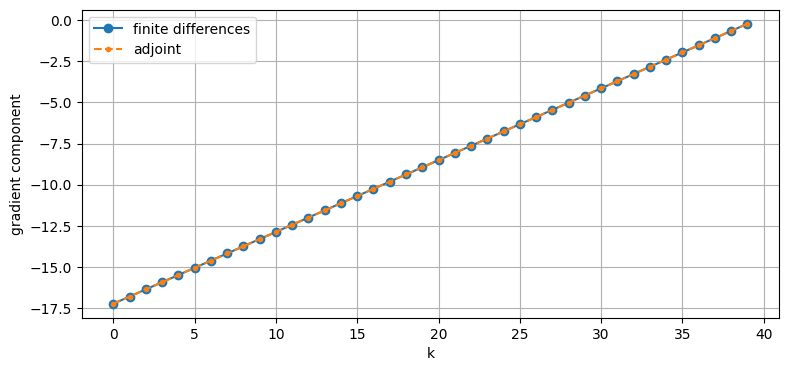

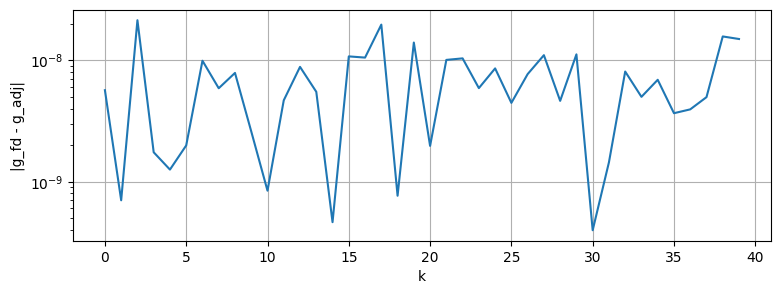

In [7]:
plt.figure(figsize=(9, 4))
plt.plot(g_fd, "o-", label="finite differences")
plt.plot(g_adj, ".--", label="adjoint")
plt.xlabel("k")
plt.ylabel("gradient component")
plt.grid()
plt.legend()
plt.show()

plt.figure(figsize=(9, 3))
plt.plot(np.abs(g_fd - g_adj))
plt.yscale("log")
plt.xlabel("k")
plt.ylabel("|g_fd - g_adj|")
plt.grid()
plt.show()

### Проверка

Объясните:

1. почему сопряжённая система решается назад;
2. почему в формуле дискретного градиента стоит $p_{k+1}$;
3. откуда появляется множитель $h$;
4. почему совпадение с finite differences является важной проверкой реализации.

**Ответы:**

1. Сначала находим состояние в конце, поэтому начальные данные для $p$ заданы в момент $T$, и решать нужно назад.
2. Управление $u_k$ влияет на $x_{k+1}$, поэтому в градиенте участвует $p_{k+1}$.
3. $u_k$ действует весь промежуток длины $h$, а дискретный градиент — это интеграл $H_u$ по этому промежутку.
4. Конечные разности считаются независимо от сопряжённой системы. Если значения совпали, значит в формулах и индексах, скорее всего, нет ошибки.

## 5. Directional derivative test

Для больших задач проверять конечными разностями каждую компоненту дорого.

Берём направление $v$ и сравниваем
$$
\nabla J(u)^{\mathsf T}v
$$
с
$$
\frac{
J(u+\varepsilon v)-J(u-\varepsilon v)
}{
2\varepsilon
}.
$$

Для каждого $\varepsilon$ требуется только два вычисления `objective`.

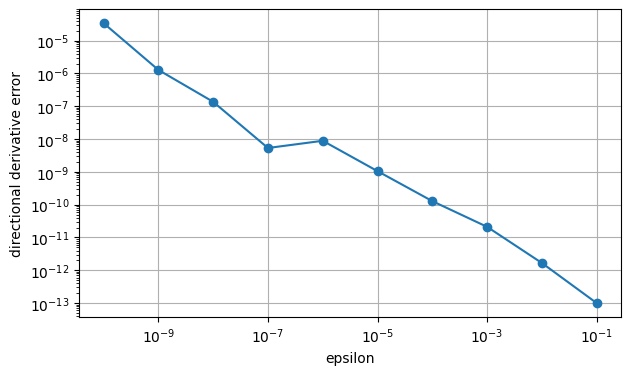

In [8]:
rng = np.random.default_rng(42)

v = rng.normal(size=N)
v /= np.linalg.norm(v)

exact_directional = g_adj @ v

eps_values = 10.0 ** (-np.arange(1, 11))
errors = []

for eps in eps_values:
    fd_directional = (
        objective(u_test + eps * v)
        - objective(u_test - eps * v)
    ) / (2 * eps)

    errors.append(
        abs(fd_directional - exact_directional)
    )

plt.figure(figsize=(7, 4))
plt.loglog(eps_values, errors, "o-")
plt.xlabel("epsilon")
plt.ylabel("directional derivative error")
plt.grid()
plt.show()

Ошибка сначала уменьшается вместе с $\varepsilon$, а затем начинает расти из-за ошибок округления.

**Вопрос:** почему нельзя брать $\varepsilon$ сколь угодно маленьким?

**Ответ:** если взять слишком маленькое $\varepsilon$, приходится вычитать почти одинаковые значения $J$. Из-за округления точность становится хуже.

## 6. Стоимость вычисления градиента

Сравним два способа при
$$
N=20,\;40,\;80,\;160.
$$

В этой реализации одна симуляция стоит $O(N)$.

- finite differences требует $O(N)$ симуляций, поэтому общая стоимость близка к $O(N^2)$;
- сопряжённый метод использует один прямой и один обратный проход, поэтому его стоимость близка к $O(N)$.

Абсолютные времена небольшие и зависят от компьютера; важна тенденция.

In [9]:
rows = []

for N_test in [20, 40, 80, 160]:
    k = np.arange(N_test)

    u = 0.2 * np.sin(
        2 * np.pi * (k + 0.5) / N_test
    )

    start = perf_counter()
    g1 = finite_difference_gradient(u)
    t_fd = perf_counter() - start

    start = perf_counter()
    g2, _ = adjoint_gradient(u)
    t_adj = perf_counter() - start

    rows.append({
        "N": N_test,
        "finite_diff_s": t_fd,
        "adjoint_s": t_adj,
        "speedup": t_fd / t_adj,
        "relative_error":
            np.linalg.norm(g1 - g2)
            / np.linalg.norm(g2),
    })

timing = pd.DataFrame(rows)
timing

,N,finite_diff_s,adjoint_s,speedup,relative_error
0,20,0.003011,0.000115,26.223861,3.702175e-10
1,40,0.009389,0.000201,46.668373,8.550777e-10
2,80,0.054524,0.000475,114.893495,1.706849e-09
3,160,0.182617,0.001076,169.647367,2.642215e-09


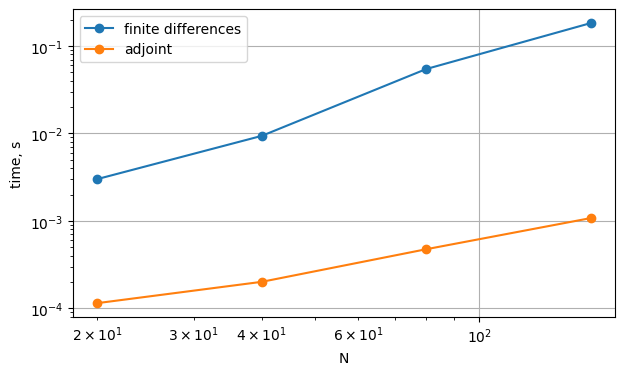

In [10]:
plt.figure(figsize=(7, 4))

plt.loglog(
    timing["N"],
    timing["finite_diff_s"],
    "o-",
    label="finite differences",
)

plt.loglog(
    timing["N"],
    timing["adjoint_s"],
    "o-",
    label="adjoint",
)

plt.xlabel("N")
plt.ylabel("time, s")
plt.grid()
plt.legend()
plt.show()

## 7. Метод проекции градиента

Для
$$
U=[-1,1]^N
$$
проекция выполняется покомпонентно:
$$
P_U(u)=\operatorname{clip}(u,-1,1).
$$

Итерация:
$$
u^{m+1}
=
P_U
\left(
u^m-\alpha\nabla J(u^m)
\right).
$$

Это простой метод. В отличие от `L-BFGS-B`, каждый его шаг полностью прозрачен.

In [11]:
def projected_gradient(
    alpha=0.06,
    maxiter=1000,
):
    u = np.zeros(N)
    history = []

    for iteration in range(maxiter):
        history.append(objective(u))

        grad, _ = adjoint_gradient(u)

        u = np.clip(
            u - alpha * grad,
            -1.0,
            1.0,
        )

    history.append(objective(u))

    return u, np.array(history)


u_pg, history_pg = projected_gradient()
x_pg = simulate(u_pg)

print("Projected gradient:")
print("J =", objective(u_pg))
print("x(T) =", x_pg[-1])

print()
print("L-BFGS-B:")
print("J =", res_ref.fun)
print("x(T) =", x_ref[-1])

Projected gradient:
J = 0.09065529341375712
x(T) = [0.99654883 0.01729232]

L-BFGS-B:
J = 0.0897152559150985
x(T) = [0.99757144 0.01206508]


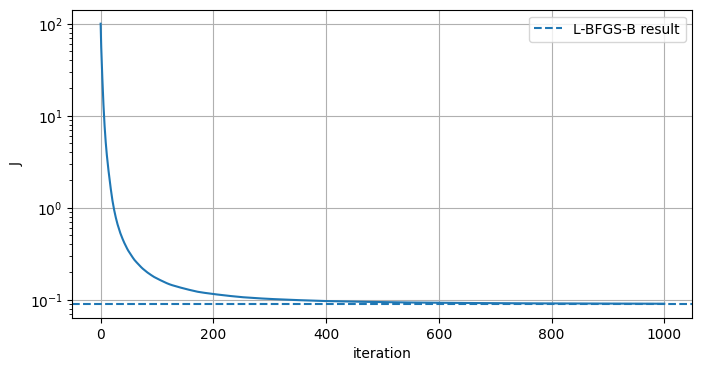

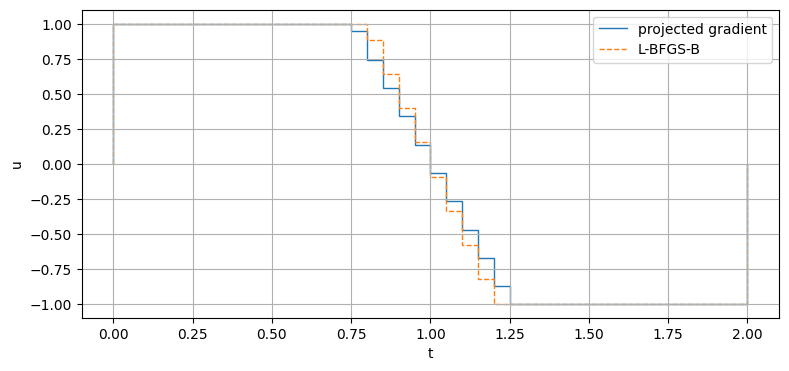

In [12]:
plt.figure(figsize=(8, 4))

plt.semilogy(history_pg)
plt.axhline(
    res_ref.fun,
    linestyle="--",
    label="L-BFGS-B result",
)

plt.xlabel("iteration")
plt.ylabel("J")
plt.grid()
plt.legend()
plt.show()


t_edges = np.linspace(0, T, N + 1)

plt.figure(figsize=(9, 4))

plt.stairs(
    u_pg,
    t_edges,
    label="projected gradient",
)

plt.stairs(
    u_ref,
    t_edges,
    linestyle="--",
    label="L-BFGS-B",
)

plt.xlabel("t")
plt.ylabel("u")
plt.ylim(-1.1, 1.1)
plt.grid()
plt.legend()
plt.show()

Проверьте также
$$
\alpha=0.01,\qquad0.03,\qquad0.06.
$$

Малый шаг даёт медленную сходимость. При слишком большом шаге функционал может перестать убывать.

## 8. Общий вид

Для задачи
$$
\dot x=f(x,u),
$$
$$
J=
\Phi(x(T))
+
\int_0^T L(x,u)\,dt
$$
вводится
$$
H=L+p^{\mathsf T}f.
$$

Основные формулы:
$$
\dot p=-H_x,
$$
$$
p(T)=\Phi_x(x(T)),
$$
$$
g(t)=H_u.
$$

Для ограниченного управления $u(t)\in U$ условие Понтрягина имеет вид
$$
u^*(t)\in
\operatorname*{arg\,min}_{u\in U}
H(x^*(t),u,p(t)).
$$

Для численного алгоритма непрерывная задача затем дискретизируется. Формула дискретного градиента должна быть согласована с выбранной дискретизацией динамики.

# Домашняя работа - срок 1 неделя

## 1. Проверка градиента при разных $N$

Для
$$
N=20,\quad40,\quad80,\quad160
$$
сравните finite-difference и adjoint gradient.

Сохраните:

- относительную ошибку;
- время finite differences;
- время adjoint;
- отношение времён.

Оформите результаты в таблицу и постройте график времени от $N$ в логарифмических осях. Коротко объясните результат.

  N finite_diff_s adjoint_s speedup relative_error
 20       0.00319   0.00020    15.8       3.15e-10
 40       0.00948   0.00027    34.8       1.15e-09
 80       0.04065   0.00048    85.4       1.55e-09
160       0.15753   0.00106   149.0       2.41e-09


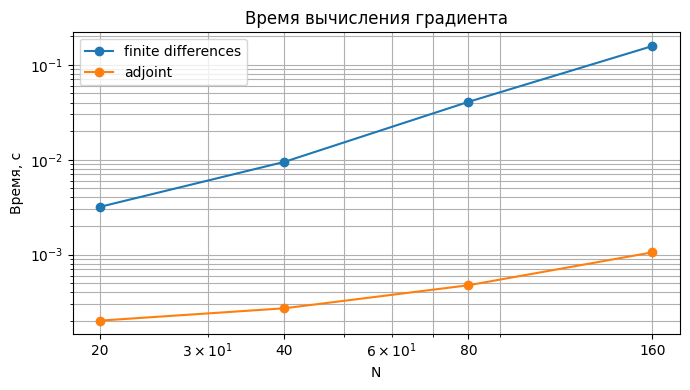

При N = 160 finite differences медленнее примерно в 149 раз.


In [13]:
# Задание 1: время и точность градиентов
rng = np.random.default_rng(7)
rows_hw = []

for n in [20, 40, 80, 160]:
    u = rng.uniform(-0.2, 0.2, n)
    times_fd = []
    times_adj = []

    # Три замера, чтобы меньше зависеть от случайных скачков времени
    for _ in range(3):
        start = perf_counter()
        g1 = finite_difference_gradient(u)
        times_fd.append(perf_counter() - start)

        start = perf_counter()
        g2, _ = adjoint_gradient(u)
        times_adj.append(perf_counter() - start)

    t1 = np.median(times_fd)
    t2 = np.median(times_adj)
    err = np.linalg.norm(g1 - g2) / np.linalg.norm(g2)

    rows_hw.append({
        "N": n,
        "finite_diff_s": t1,
        "adjoint_s": t2,
        "speedup": t1 / t2,
        "relative_error": err,
    })

task1 = pd.DataFrame(rows_hw)
print(task1.to_string(index=False, formatters={
    "finite_diff_s": "{:.5f}".format,
    "adjoint_s": "{:.5f}".format,
    "speedup": "{:.1f}".format,
    "relative_error": "{:.2e}".format,
}))

assert (task1["relative_error"] < 1e-6).all()

plt.figure(figsize=(7, 4))
plt.loglog(task1["N"], task1["finite_diff_s"], "o-", label="finite differences")
plt.loglog(task1["N"], task1["adjoint_s"], "o-", label="adjoint")
plt.xticks([20, 40, 80, 160], [20, 40, 80, 160])
plt.xlabel("N")
plt.ylabel("Время, с")
plt.title("Время вычисления градиента")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.show()

print(f"При N = 160 finite differences медленнее примерно в {task1.iloc[-1]['speedup']:.0f} раз.")

**Вывод:** конечные разности при увеличении $N$ становятся заметно медленнее. У сопряжённого метода время растёт намного слабее, а относительная ошибка остаётся маленькой — обе реализации дают один и тот же градиент.

## 2. Выбор $\varepsilon$

Для $N=40$ выполните directional derivative test при
$$
\varepsilon=10^{-1},10^{-2},\ldots,10^{-12}.
$$

Постройте ошибку в логарифмических осях.

Укажите:

1. где ошибка уменьшается;
2. при каком порядке $\varepsilon$ она примерно минимальна;
3. почему затем начинается рост.

Первые 5 значений u: [-0.0318  0.1703 -0.0905 -0.176  -0.0758]
G @ v = -13.434060296
epsilon   finite_diff abs_error
  1e-01 -13.434060296 1.776e-14
  1e-02 -13.434060296 4.441e-13
  1e-03 -13.434060296 1.021e-11
  1e-04 -13.434060296 9.637e-11
  1e-05 -13.434060295 3.095e-10
  1e-06 -13.434060293 3.152e-09
  1e-07 -13.434060264 3.157e-08
  1e-08 -13.434060264 3.157e-08
  1e-09 -13.434053869 6.426e-06
  1e-10 -13.434018342 4.195e-05
  1e-11 -13.433520962 5.393e-04
  1e-12 -13.436363133 2.303e-03
Минимальная ошибка: 1.78e-14 при epsilon = 1e-01


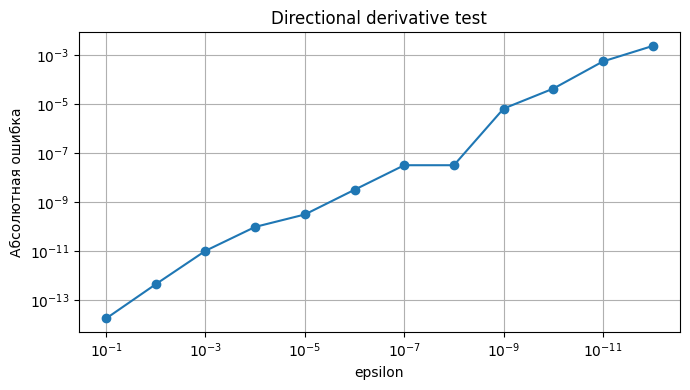

In [14]:
# Задание 2: проверка производной по направлению
rng = np.random.default_rng(19)
u_eps = rng.uniform(-0.2, 0.2, N)
v_eps = rng.normal(size=N)
v_eps /= np.linalg.norm(v_eps)

g_eps, _ = adjoint_gradient(u_eps)
exact = g_eps @ v_eps

eps_hw = 10.0 ** (-np.arange(1, 13))
fd_hw = []
err_hw = []

for eps in eps_hw:
    val = (objective(u_eps + eps * v_eps) - objective(u_eps - eps * v_eps)) / (2 * eps)
    fd_hw.append(val)
    err_hw.append(abs(val - exact))

task2 = pd.DataFrame({
    "epsilon": eps_hw,
    "finite_diff": fd_hw,
    "abs_error": err_hw,
})
print("Первые 5 значений u:", np.round(u_eps[:5], 4))
print(f"G @ v = {exact:.9f}")
print(task2.to_string(index=False, formatters={
    "epsilon": "{:.0e}".format,
    "finite_diff": "{:.9f}".format,
    "abs_error": "{:.3e}".format,
}))

i_best = int(np.argmin(err_hw))
print(f"Минимальная ошибка: {err_hw[i_best]:.2e} при epsilon = {eps_hw[i_best]:.0e}")

plt.figure(figsize=(7, 4))
plt.loglog(eps_hw, err_hw, "o-")
plt.gca().invert_xaxis()
plt.xlabel("epsilon")
plt.ylabel("Абсолютная ошибка")
plt.title("Directional derivative test")
plt.grid(True, which="both")
plt.tight_layout()
plt.show()

**Вывод:** здесь нет обязательного начального уменьшения ошибки. Для двойного интегратора $J(u)$ — квадратичная функция, а центральная разность для неё точна без учёта округления. Поэтому на крупных $\varepsilon$ ошибка уже очень маленькая, а при $10^{-8}$–$10^{-12}$ обычно растёт из-за вычитания близких чисел. Минимум для конкретного теста напечатан выше.

## 3. Выбор шага projected gradient

Запустите метод при
$$
\alpha=0.01,\quad0.03,\quad0.06.
$$

На одном рисунке постройте три зависимости
$$
m\mapsto J_m
$$
и горизонтальную линию с результатом `L-BFGS-B`.

Сравните скорость сходимости и конечное значение функционала.

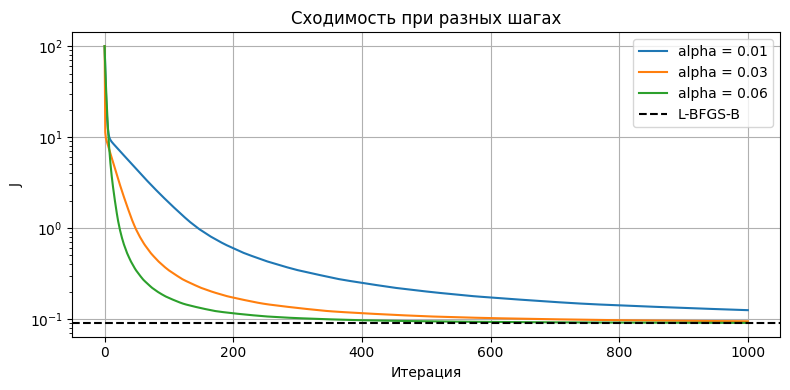

L-BFGS-B: J = 0.08971526
alpha    J_100   J_1000 difference
 0.01 1.899204 0.125085   0.035370
 0.03 0.342378 0.094411   0.004696
 0.06 0.170435 0.090655   0.000940


In [15]:
# Задание 3: сравнение шагов projected gradient
rows_pg = []
plt.figure(figsize=(8, 4))

for alpha in [0.01, 0.03, 0.06]:
    u, history = projected_gradient(alpha=alpha, maxiter=1000)
    rows_pg.append({
        "alpha": alpha,
        "J_100": history[100],
        "J_1000": history[-1],
        "difference": history[-1] - res_ref.fun,
    })
    plt.semilogy(history, label=f"alpha = {alpha}")

plt.axhline(res_ref.fun, color="black", linestyle="--", label="L-BFGS-B")
plt.xlabel("Итерация")
plt.ylabel("J")
plt.title("Сходимость при разных шагах")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

task3 = pd.DataFrame(rows_pg)
print("L-BFGS-B: J =", round(res_ref.fun, 8))
print(task3.to_string(index=False, formatters={
    "alpha": "{:.2f}".format,
    "J_100": "{:.6f}".format,
    "J_1000": "{:.6f}".format,
    "difference": "{:.6f}".format,
}))

**Вывод:** из трёх шагов быстрее всего сходится $\alpha=0.06$. Шаг $0.01$ слишком маленький: даже после 1000 итераций результат хуже. `L-BFGS-B` всё равно достигает меньшего значения $J$.

## 4. Маятник

Рассмотрим
$$
\dot\theta=\omega,
$$
$$
\dot\omega=-\sin\theta+u.
$$

Параметры:
$$
T=5,\qquad
(\theta(0),\omega(0))=(0,0),
$$
$$
(\theta_{\mathrm{target}},\omega_{\mathrm{target}})
=
(\pi,0),
$$
$$
J=
20(\theta(T)-\pi)^2+
5\omega(T)^2+
0.05\int_0^T u^2(t)\,dt.
$$

### Теоретическая часть

1. Выпишите функцию Гамильтона-Понтрягина.
2. Получите сопряжённую систему.
3. Выпишите терминальное условие.
4. Получите непрерывный градиент $H_u$.

### Численная часть

Используйте явный Euler:
$$
\theta_{k+1}
=
\theta_k+h\omega_k,
$$
$$
\omega_{k+1}
=
\omega_k+h(-\sin\theta_k+u_k).
$$

Возьмите
$$
N=100.
$$

Для дискретного шага
$$
F_x=
\begin{pmatrix}
1 & h\\
-h\cos\theta_k & 1
\end{pmatrix},
\qquad
F_u=
\begin{pmatrix}
0\\
h
\end{pmatrix}.
$$

Требуется:

1. написать `simulate_pendulum`;
2. написать `objective_pendulum`;
3. реализовать дискретный adjoint gradient;
4. проверить его directional derivative test на случайном управлении с небольшими компонентами.

Оптимизировать маятник пока не требуется.

### Теоретическая часть

Гамильтониан:
$$
H=0.05u^2+p_1\omega+p_2(-\sin\theta+u).
$$

Сопряжённая система:
$$
\dot p_1=p_2\cos\theta, \qquad \dot p_2=-p_1.
$$

Условия в конце отрезка:
$$
p_1(T)=40(\theta(T)-\pi),\qquad p_2(T)=10\omega(T).
$$

Непрерывный градиент:
$$
H_u=0.1u+p_2.
$$

Для явного Эйлера используется дискретный градиент $G_k=0.1h u_k+h p_{2,k+1}$.

In [16]:
T_p = 5.0
N_p = 100
h_p = T_p / N_p

x0_p = np.array([0.0, 0.0])
x_target_p = np.array([np.pi, 0.0])

w_theta = 20.0
w_omega = 5.0
lam_p = 0.05


def simulate_pendulum(u):
    h = T_p / len(u)
    x = np.zeros((len(u) + 1, 2))
    x[0] = x0_p

    for k in range(len(u)):
        theta, omega = x[k]
        x[k + 1, 0] = theta + h * omega
        x[k + 1, 1] = omega + h * (-np.sin(theta) + u[k])

    return x


def objective_pendulum(u):
    h = T_p / len(u)
    x = simulate_pendulum(u)
    e = x[-1] - x_target_p

    return (
        w_theta * e[0]**2
        + w_omega * e[1]**2
        + lam_p * h * np.sum(u**2)
    )


def adjoint_gradient_pendulum(u):
    h = T_p / len(u)
    x = simulate_pendulum(u)
    p = np.zeros_like(x)
    grad = np.zeros(len(u))

    e = x[-1] - x_target_p
    p[-1] = [2 * w_theta * e[0], 2 * w_omega * e[1]]

    for k in range(len(u) - 1, -1, -1):
        Fx = np.array([
            [1.0, h],
            [-h * np.cos(x[k, 0]), 1.0],
        ])

        grad[k] = 2 * lam_p * h * u[k] + h * p[k + 1, 1]
        p[k] = Fx.T @ p[k + 1]

    return grad, p

Первые 5 значений u: [-0.1284  0.056  -0.0131 -0.0518 -0.058 ]
J(u) = 197.595704
x(T) = [-0.001567  0.028009]
G @ v = -3.985895724
epsilon  finite_diff abs_error
  1e-01 -3.985897583 1.859e-06
  1e-02 -3.985895743 1.859e-08
  1e-03 -3.985895724 1.954e-10
  1e-04 -3.985895724 9.594e-11
  1e-05 -3.985895725 9.486e-10
  1e-06 -3.985895731 6.633e-09
  1e-07 -3.985895773 4.927e-08
  1e-08 -3.985896058 3.335e-07
Минимальная ошибка: 9.59e-11 при epsilon = 1e-04


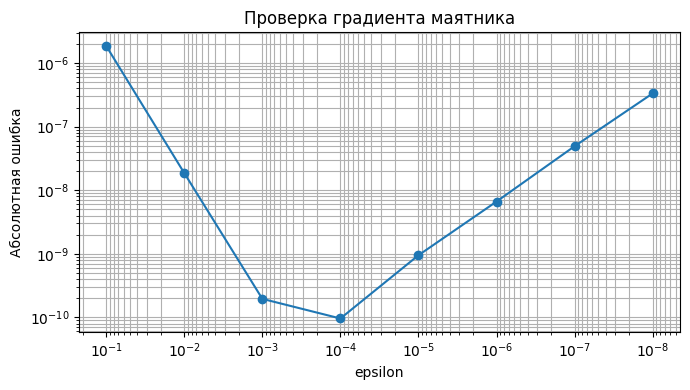

In [17]:
# Задание 4: численная проверка градиента маятника
rng = np.random.default_rng(2026)
u_p_test = rng.uniform(-0.2, 0.2, N_p)
v_p = rng.normal(size=N_p)
v_p /= np.linalg.norm(v_p)

g_p, p_p = adjoint_gradient_pendulum(u_p_test)
exact_p = g_p @ v_p

eps_p = 10.0 ** (-np.arange(1, 9))
errors_p = []
fd_p = []

for eps in eps_p:
    val = (objective_pendulum(u_p_test + eps * v_p)
           - objective_pendulum(u_p_test - eps * v_p)) / (2 * eps)
    fd_p.append(val)
    errors_p.append(abs(val - exact_p))

task4 = pd.DataFrame({
    "epsilon": eps_p,
    "finite_diff": fd_p,
    "abs_error": errors_p,
})
print("Первые 5 значений u:", np.round(u_p_test[:5], 4))
print(f"J(u) = {objective_pendulum(u_p_test):.6f}")
print("x(T) =", np.round(simulate_pendulum(u_p_test)[-1], 6))
print(f"G @ v = {exact_p:.9f}")
print(task4.to_string(index=False, formatters={
    "epsilon": "{:.0e}".format,
    "finite_diff": "{:.9f}".format,
    "abs_error": "{:.3e}".format,
}))

best_p = int(np.argmin(errors_p))
print(f"Минимальная ошибка: {errors_p[best_p]:.2e} при epsilon = {eps_p[best_p]:.0e}")
assert errors_p[3] < 1e-6

plt.figure(figsize=(7, 4))
plt.loglog(eps_p, errors_p, "o-")
plt.gca().invert_xaxis()
plt.xlabel("epsilon")
plt.ylabel("Абсолютная ошибка")
plt.title("Проверка градиента маятника")
plt.grid(True, which="both")
plt.tight_layout()
plt.show()

**Вывод:** directional derivative test подтверждает, что градиент маятника посчитан правильно: для среднего $\varepsilon$ ошибки очень маленькие. В отличие от двойного интегратора, здесь в обратном проходе матрица $F_x$ зависит от текущего угла $\theta_k$.

## Итог

В нескольких предложениях ответьте:

- почему finite differences плохо масштабируется по числу компонент управления;
- что вычисляет сопряжённая система;
- зачем нужен gradient check;
- чем projected gradient отличается от `L-BFGS-B`;
- что изменилось в формулах после перехода к нелинейному маятнику.

## Перед сдачей

- `Restart Kernel -> Run All`;
- все численные выводы должны получаться из кода;
- повторяющийся код вынесите в функции;
- подпишите оси и легенды.

### Ответы по итогам

1. **Finite differences** требует две симуляции на каждую компоненту $u$, поэтому плохо работает при большом $N$.
2. **Сопряжённая система** помогает вычислить влияние управления на конечный функционал одним обратным проходом.
3. **Gradient check** нужен, чтобы проверить знаки, индексы и формулу градиента до запуска оптимизации.
4. **Projected gradient** делает простой шаг по градиенту с обрезанием до $[-1,1]$, а `L-BFGS-B` выбирает шаг и направление более продвинутым способом.
5. **Для маятника** появилась нелинейность $\sin\theta$. Поэтому $F_x$ зависит от траектории и пересчитывается на каждом шаге.